# ¿Qué equilibra realmente el objetivo conjunto?

**Pregunta:** ¿Cómo cambia la escala del término estructural y sus derivadas al variar solo la longitud de acoplamiento?

**Nivel 2 — objetivo y derivadas**  
**Prerrequisitos:** hipótesis inversa conjunta, mínimos cuadrados ponderados y derivadas direccionales; 35 min.

## Objetivos

Separar desajuste de datos, regularización de propiedades y acoplamiento estructural; seguir el efecto de la longitud en el término estructural del producto; distinguir gradiente y producto Hessiano-vectorial de incertidumbre y capacidad predictiva.

## Preparación

Instale las dependencias exactas del notebook:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 simpeg==0.25.2 discretize==0.12.0
```

Se conserva el mismo control diseñado de doce celdas, plan, máscara activa y vectores de densidad y susceptibilidad; no hay datos de campo y los modelos no se reajustan.

## Datos

El control fijo registra coordenadas receptoras, metadatos de fuente, declaraciones de incertidumbre, doce celdas activas y vectores acotados de propiedades físicas. Son entradas sintéticas diseñadas, no observaciones. Cada longitud usa los mismos arreglos de adquisición y modelo para que solo varíe el factor declarado.

## Método

Un objetivo conjunto puede escribirse φ = φd,ρ + φd,χ + βρRρ + βχRχ + λC. Cada término de datos usa la respuesta directa y covarianza de su modalidad; los regularizadores expresan supuestos separados; C representa compatibilidad de gradiente cruzado. Aquí se aísla C y se cambia su longitud con campos fijos. En esta implementación la longitud entra con factor de cuarta potencia y normalización por volumen activo. La respuesta de escala pertenece a la parametrización, no expresa preferencia empírica.

El gradiente es el cambio de primer orden de C en un modelo. El producto Hessiano-vectorial describe el cambio local de segundo orden en una dirección. Ninguno es covarianza de datos ni incertidumbre posterior. La diferencia finita puede revelar errores de derivación, no establecer calidad de optimización. Elegir λ o longitud requiere validación predefinida con observaciones independientes y una regla de decisión.


In [1]:
# Importe el evaluador físico fijado y muestre las versiones del entorno.
from pathlib import Path
import sys
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline/joint_survey_structure.py").is_file()
)
sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_plan as planner
import joint_survey_structure as physical_structure

print("NumPy", version("numpy"), "SimPEG", version("simpeg"), "discretize", version("discretize"))


NumPy 2.2.6 SimPEG 0.25.2 discretize 0.12.0


### El control físico permanece fijo

Las doce celdas activas, coordenadas receptoras, límites y escalas quedan iguales en cada solicitud. Así, la longitud es el único factor experimental. Seis receptores por modalidad y declaraciones de ruido describen adquisición sintética; no entran residuos observados al barrido. Se aísla el escalamiento del regularizador, no se comparan ajustes gravimétricos y magnéticos.


In [2]:
# Defina un control ENU pequeño de creación propia y sus escalas físicas declaradas.
receivers = np.array(
    [20, 30, 100, 50, 80, 110, -90, 40, 130, 10, -10, 150, 90, -50, 120, 130, 40, 160], dtype=float
).reshape(6, 3)
mag_receivers = receivers + [5, 0, 0]
src = dict(
    citation="Authored numerical control, not field data",
    raw_bytes=123,
    rights="private_use",
    correction_sha256="c" * 64,
)
g_source = dict(src, source_id="gravity", raw_sha256="a" * 64)
m_source = dict(src, source_id="magnetic", raw_sha256="b" * 64)
noise = dict(basis="measured_gaussian", cross_partition="declared_absent", citation="Authored error control")
noise_g = dict(noise, kind="diagonal_sd", unit="mGal")
noise_m = dict(noise, kind="diagonal_sd", unit="nT")
common = dict(reference_id="authored-local-enu", mask=np.zeros(6, bool), missing_reasons=("",) * 6)
common.update(groups=np.array([0, 0, 1, 1, 2, 2]), partition=np.array([0, 0, 1, 1, 2, 2]))
gravity = dict(common, source=g_source, component="gz_up", unit="mGal", receivers_m=receivers, noise=noise_g)
field = dict(amplitude_nt=50000.0, inclination_deg=60.0, declination_deg=12.0)


### Mantener separados los términos de datos

Las observaciones gravimétricas y magnéticas tienen unidades, operadores, supuestos de fuente y errores distintos. Un objetivo defendible blanquea cada residuo con su covarianza e informa cada término antes de agregar regularización y acoplamiento. De otro modo, una modalidad podría dominar por sus unidades o cantidad de muestras. Este experimento grafica solo gradiente cruzado, no mejora del objetivo total.


In [3]:
# Conserve escalas y orden de malla declarados: ambos intervienen en la derivada discreta.
magnetic = dict(
    common,
    source=m_source,
    component="linear_tmi",
    unit="nT",
    receivers_m=mag_receivers,
    noise=noise_m,
    inducing_field=field,
)
density = dict(
    lower=np.full(12, -1500.0),
    upper=np.full(12, 1500.0),
    start=np.zeros(12),
    reference=np.zeros(12),
    scale=750.0,
)
susceptibility = dict(
    lower=np.zeros(12),
    upper=np.full(12, 0.1),
    start=np.full(12, 0.005),
    reference=np.full(12, 0.005),
    scale=0.03,
)


### La huella del plan fija la comparación

El resumen del plan normalizado registra malla y levantamiento consumidos por el evaluador. Mantenerlo constante asegura que los puntos posteriores usen la misma geometría y orden paramétrico. Una huella coincidente no demuestra que el control diseñado represente un sondeo real; solo evita confundir cambios de entrada con el efecto de longitud.


In [4]:
# Conserve escalas y orden de malla declarados: ambos intervienen en la derivada discreta.
frame = dict(
    kind="local_cartesian",
    axes=("east", "north", "up"),
    length_unit="m",
    vertical_positive="up",
    reference_id="authored-local-enu",
)
frame.update(horizontal_datum="declared local origin", vertical_datum="declared elevation datum")
mesh = dict(
    origin_m=np.array([-140.0, -180.0, -260.0]),
    hx_m=np.array([40.0, 70.0, 90.0]),
    hy_m=np.array([30.0, 50.0]),
    hz_m=np.array([60.0, 110.0]),
    active=np.ones(12, bool),
)
prior = dict(
    density=density,
    susceptibility=susceptibility,
    lengths_m=np.array([60.0, 110.0, 75.0]),
    coupling_length_m=100.0,
    basis="Declared physical scales",
)


### Paso 1 — fijar la referencia

Evalúe el término estructural en la longitud base. Ancla el barrido, pero no es benchmark. Con campos fijos, no informa si ajustan datos observados, si concuerdan inversiones separadas ni si el acoplamiento mejora la interpretación.


In [5]:
# Valide unidades, celdas activas y grupos antes de evaluar la cantidad estructural conjunta.
policy = dict(
    name="joint-survey-l2-cross-gradient-1", seed=42, cell_order="x-fast", training="not_applicable_classical"
)
policy.update(group_scope="global_acquisition", modal_covariance="independent")
physical_request = dict(
    schema="joint-survey-plan-request-1",
    frame=frame,
    mesh=mesh,
    gravity=gravity,
    magnetic=magnetic,
    prior=prior,
    policy=policy,
)
physical_plan = planner.plan_joint_survey(physical_request)
physical_n = 12
physical_rho, physical_chi = np.linspace(-400.0, 500.0, 12), np.linspace(0.004, 0.045, 12) + 0.002 * np.sin(
    np.arange(12)
)
physical_direction = np.sin(np.arange(24) + 0.3) / np.linalg.norm(np.sin(np.arange(24) + 0.3))
print("celdas activas creadas", int(physical_plan["mesh"]["active"].sum()), "número de receptores", len(receivers))


celdas activas creadas 12 número de receptores 6


### Paso 2 — variar solo la longitud

Construya solicitudes con campos y plan idénticos, cambiando únicamente longitud. El factor de cuarta potencia implica incrementos desiguales del objetivo ante cambios aditivos iguales. El intervalo explica sensibilidad: no recomienda una escala de campo ni es búsqueda de hiperparámetros. No se ordenan puntos con datos reservados.


In [6]:
# Evalúe el término estructural físico de referencia.
r = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
print("objetivo", r['objective'], "plan", r["plan_sha256"])


objetivo 0.012770248999752326 plan c62903164d0f129d95137ffe16f334e3cf0d936d26f1f8fa04c6d4da3da9563c


### Paso 3 — examinar curvatura local

El producto Hessiano-vectorial describe cómo cambia el gradiente del prior a lo largo de una dirección. Depende de escala, malla y dirección. No es covarianza, intervalo de incertidumbre ni espectro completo; una dirección no revela todas las combinaciones débilmente restringidas.


In [7]:
# Cambie solo la longitud de acoplamiento en el barrido de sensibilidad declarado.
from copy import deepcopy

lengths = np.array([50.0, 75.0, 100.0, 150.0, 200.0])
values = []
for length in lengths:
    q = deepcopy(physical_request)
    q["prior"]["coupling_length_m"] = float(length)
    values.append(
        physical_structure.evaluate_joint_structure(
            {
                "schema": "joint-survey-structure-request-1",
                "survey_request": q,
                "density_kg_m3": physical_rho,
                "susceptibility_si": physical_chi,
                "direction_physical": physical_direction,
            }
        )['objective']
    )
print("length_m", lengths.tolist(), "objetivo", np.round(values, 8).tolist())


length_m [50.0, 75.0, 100.0, 150.0, 200.0] objetivo [0.00079814, 0.00404059, 0.01277025, 0.06464939, 0.20432398]


### Paso 4 — comprobar la derivada

Compare derivada direccional analítica con diferencia finita central en la referencia. La brecha prueba implementación local para un tamaño de perturbación. No se evalúan otras direcciones, cancelación ni comportamiento no suave. Es evidencia de una derivada, no análisis numérico completo ni garantía de convergencia.


In [8]:
# Vuelva a evaluar los mismos campos físicos con la dirección opuesta.
from copy import deepcopy

reverse_request = deepcopy(physical_request)
reverse_request["prior"]["coupling_length_m"] = 100.0
exact = np.asarray(r["exact_hessian_vector_physical"])
reverse_request_result = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": reverse_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": -physical_direction,
    }
)
reverse_hv = np.asarray(reverse_request_result["exact_hessian_vector_physical"])
assert np.allclose(reverse_hv, -exact, rtol=1e-10, atol=1e-12)
print("paridad impar del producto Hessiano-vector", float(np.max(np.abs(reverse_hv + exact))))


paridad impar del producto Hessiano-vector 0.0


### Paso 5 — no confundir cantidades

El barrido del objetivo aparece junto a la norma del gradiente base. Tienen funciones matemáticas distintas; la línea no es una meta. Una curva empinada no significa mejor ajuste, y un gradiente pequeño no prueba mínimo del objetivo completo. Lea cada eje por separado: el modelo permanece fijo.


In [9]:
# Verifique el gradiente físico mediante diferencias finitas centrales.
h = 1e-3


def f(a, b):
    return physical_structure.evaluate_joint_structure(
        {
            "schema": "joint-survey-structure-request-1",
            "survey_request": physical_request,
            "density_kg_m3": a,
            "susceptibility_si": b,
            "direction_physical": physical_direction,
        }
    )['objective']


fd = (
    f(physical_rho + h * physical_direction[:physical_n], physical_chi + h * physical_direction[physical_n:])
    - f(physical_rho - h * physical_direction[:physical_n], physical_chi - h * physical_direction[physical_n:])
) / (2 * h)
print(
    "derivada direccional analítica",
    float(np.dot(r["gradient_physical"], physical_direction)),
    "diferencia finita",
    fd,
)


derivada direccional analítica 3.5699340755498583 diferencia finita 3.569933992523068


### Graficar barrido de escala y derivada

Los paneles muestran el objetivo estructural recién calculado para varias longitudes y la norma del gradiente en la solicitud base. Mantenga ejes separados: valor del prior y magnitud de derivada son diagnósticos distintos. Las interpretaciones siguientes examinan cada panel de forma independiente.


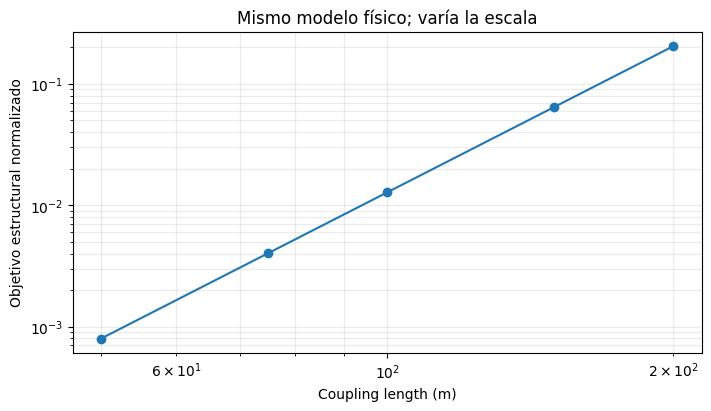

In [10]:
# Grafique la respuesta calculada; cambiar esta escala no es ajustar una inversión.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.loglog(lengths, values, "o-")
ax.set(
    xlabel="Coupling length (m)",
    ylabel="Objetivo estructural normalizado",
    title="Mismo modelo físico; varía la escala",
)
ax.grid(True, which="both", alpha=0.25)
plt.show()


### Interpretación de figura 1: escala del objetivo

El objetivo crece de 0.000798 a 0.204324 entre 50 y 200 m con campos fijos. La respuesta expone el escalamiento de cuarta potencia declarado, no una mejora del ajuste gravimétrico o magnético. No se reajusta el modelo ni se ordenan configuraciones con observaciones de validación. La curva documenta sensibilidad de parametrización.


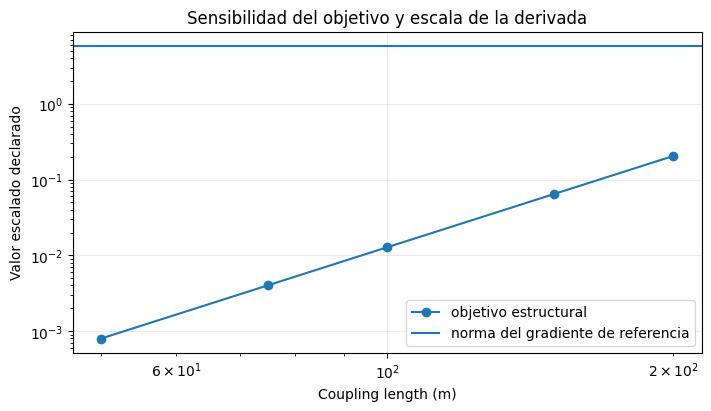

caso joint-control-00 objetivo 32.97655447858452
términos componentes {'data_gravity': 18.89476419413715, 'regularization_gravity': 0.0, 'data_magnetic': 14.081790284447372, 'regularization_magnetic': 0.0, 'coupling': 0.0}


In [11]:
# Grafique la respuesta de escala junto a la magnitud distinta de la derivada.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.loglog(lengths, values, "o-", label="objetivo estructural")
ax.axhline(np.linalg.norm(r["gradient_physical"]), label="norma del gradiente de referencia")
ax.set(
    xlabel="Coupling length (m)",
    ylabel="Valor escalado declarado",
    title="Sensibilidad del objetivo y escala de la derivada",
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

# Compile, planifique, compile y evalúe el objetivo real del producto con entradas sintéticas idénticas.
import joint_survey_cases, joint_survey_compiled, joint_survey_objective

joint_control = joint_survey_cases.make_joint_control(0)
joint_problem = joint_survey_compiled.compile_joint_development({
    "schema": "joint-survey-compile-request-1",
    "survey_request": joint_control["survey_request"],
    "development": joint_control["development"],
})
prior_product = joint_control["survey_request"]["prior"]
joint_result = joint_survey_objective.evaluate_joint_objective({
    "schema": "joint-survey-objective-request-1",
    "survey_request": joint_control["survey_request"],
    "development": joint_control["development"],
    "models": {
        "density_kg_m3": prior_product["density"]["start"],
        "susceptibility_si": prior_product["susceptibility"]["start"],
    },
    "direction_physical": np.zeros(24),
    "weights": {"beta_gravity": 1e-4, "beta_magnetic": 1e-4, "coupling": 0.1},
})
print("caso", joint_control["case_id"], "objetivo", joint_result["objective"])
print("términos componentes", joint_result["terms"])
assert set(joint_result["terms"]) == {"data_gravity", "regularization_gravity", "data_magnetic", "regularization_magnetic", "coupling"}
assert joint_result["diagnostics"]["inverse_completed"] is False


### Interpretación de figura 2: derivada de referencia

La norma del gradiente corresponde a la solicitud base y no es meta ni segunda curva del objetivo. Su magnitud describe el cambio local del término estructural respecto de la dirección declarada del modelo. No es incertidumbre ni evidencia de convergencia. Leerla por separado evita confundir escala visual con calidad predictiva.




## Resultados

**Respuesta:** Con campos fijos, cambiar longitud de 50 a 200 m mueve el objetivo estructural de 0.00079814 a 0.20432398. Documenta escalamiento no lineal, no inversión ni selección.

## Resumen

Este notebook aísla acoplamiento y derivadas. Una inversión real debe equilibrar desajustes por modalidad, covarianzas y regularización. La selección debe apoyarse en datos de validación, no en la apariencia de la curva.

## Referencias

- Cockett et al. (2015), [SimPEG](https://doi.org/10.1016/j.cageo.2015.09.015)
- [Tutorial de gradiente cruzado de SimPEG](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- `data-pipeline/joint_survey_plan.py`; `data-pipeline/joint_survey_structure.py`